In [1]:
import math
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

# Walk up from the notebook folder to locate the repository's `code/` root
CODE_DIR = next(
    (c for p in (Path.cwd(), *Path.cwd().parents) for c in (p, p / "code") if all((c / d).is_dir() for d in ("kev", "data", "models"))),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"No code/ root containing kev/, data/, and models/ at or above {Path.cwd()}")

# The `beta_ols` package (and this notebook's other modules) is in `src/` next to this notebook
EXPLORATION_DIR = CODE_DIR / "papers" / "beta-loss" / "exploration"
SRC_DIR = EXPLORATION_DIR / "src"
if not (SRC_DIR / "beta_ols").is_dir():
    raise RuntimeError(f"`beta_ols` package not found in {SRC_DIR}")

# Run from `code/` and expose `code/`, `code/kev/`, and `src/` on sys.path
os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev"), str(SRC_DIR)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from dataclasses import replace

from models.kev_pointer import KevPointerModel
from training import free_gpu

import beta_ols
from beta_ols import core as beta_core
from beta_train.config import TrainConfig, scale_lr_for_sample_size
from beta_train.diagnostics import find_max_micro_chunk, gradient_check
from beta_train.items import build_items_cached, items_summary
from beta_train.model_state import reset_trainable, snapshot_trainable
from beta_train.reports import best_beta_table, best_table, comparison_table, eval_beta_table, mse_decomposition, per_dataset_table
from beta_train.runs import load_best
from beta_train.trainer import RunResult, load_run, run_training
from beta_train.validation import PopulationValidator, TrainingPathValidator, validate_all_cached, validation_metrics_frame

# Disk cache for training items and the untrained (step-0) validation; delete the folder to clear it
CACHE_DIR = CODE_DIR / ".cache" / "beta_training"

print(f"CODE_DIR: {CODE_DIR}")

CODE_DIR: /home/dw/github/decision-models-finetuning/code


In [2]:
# Require CUDA and release any previously loaded `kev_model` before allocating a fresh 800M backbone
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is required to run jaredpalmer/kev-0.8b in bf16 train mode")
if "kev_model" in globals():
    globals().pop("kev_model")
device = "cuda"
free_gpu()
torch.manual_seed(42)

# Model settings (also the key of the cached step-0 validation)
KEV_BASE = "jaredpalmer/kev-0.8b"
LORA_RANK = 64
WEIGHTS_DTYPE = "bf16"
HEAD_TEMPERATURE = 1.0   # training uses raw uncalibrated temperature = 1.0

# Build the frozen backbone + LoRA + pointer head
t_model0 = time.perf_counter()
kev_model = KevPointerModel.build(
    KEV_BASE,
    device=device,
    lora_rank=LORA_RANK,
    weights_dtype=WEIGHTS_DTYPE,
)
kev_model.net.head.temperature = HEAD_TEMPERATURE
kev_model.train()                     # enable training mode (LoRA dropout active, trainable params require_grad)
torch.cuda.synchronize()
model_load_sec = time.perf_counter() - t_model0

trainable_params_count = sum(p.numel() for p in kev_model.trainable_parameters())
total_params_count = sum(p.numel() for p in kev_model.parameters())
display(
    pd.Series(
        {
            "base_model": KEV_BASE,
            "mode": kev_model.mode,
            "training": kev_model.training,
            "weights_dtype": kev_model.meta.weights_dtype,
            "lora_rank": kev_model.meta.lora,
            "trainable_params": f"{trainable_params_count:,}",
            "total_params": f"{total_params_count:,}",
            "model_load_sec": round(model_load_sec, 3),
        },
        name="kev_800m_train_mode",
    ).to_frame()
)

# Snapshot the untrained trainable weights right after building, so every run, diagnostic, and the step-0
# validation start from them (rebuilding the model re-snapshots)
INIT_TRAINABLE_STATE = snapshot_trainable(kev_model)
MODEL_KEY = {"base": KEV_BASE, "lora_rank": LORA_RANK, "weights_dtype": WEIGHTS_DTYPE, "head_temperature": HEAD_TEMPERATURE}
print(f"Snapshotted {len(INIT_TRAINABLE_STATE)} trainable tensors")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,kev_800m_train_mode
base_model,jaredpalmer/kev-0.8b
mode,lora_rank 64
training,True
weights_dtype,bf16
lora_rank,64
trainable_params,"43,815,424"
total_params,"796,208,448"
model_load_sec,1.703


Snapshotted 376 trainable tensors


# Datasets (loaded and replicated through `beta_ols`)

In [3]:
# Datasets this notebook uses; only these are loaded (the others are skipped to save time)
ITEM_DATASETS = [         # training items are built for these (training, gradient check, VRAM search)
    # "wu2025",
    "berke2023",
    # "kriner2026"

]
VALIDATION_DATASETS = [   # validation runs on these
    "grummon2025",
    "kriner2026",
]
LOADED_DATASETS = list(ITEM_DATASETS)
for dataset_name in VALIDATION_DATASETS:
    if dataset_name not in LOADED_DATASETS:
        LOADED_DATASETS.append(dataset_name)

# Load each through its `beta_ols` module: task rows, regression rows, regression specs, human OLS replication.
# Validation uses the whole dataset. Training splits a dataset with several task variables (`v`) into one pseudo
# dataset per task ("<dataset>/<v>"), so an item holds one respondent's tasks of a single kind.
choice_dfs: dict[str, pd.DataFrame] = {}
regression_rows_by_dataset: dict[str, pd.DataFrame] = {}
regression_specs_by_dataset: dict[str, dict] = {}
human_ols_by_dataset: dict[str, pd.DataFrame] = {}
module_by_dataset = {}    # (pseudo) dataset name -> the beta_ols module that codes its rows
TRAIN_DATASETS = []       # pseudo datasets of ITEM_DATASETS, the names training uses

for dataset_name in LOADED_DATASETS:
    dataset_module = beta_ols.DATASET_MODULES[dataset_name]
    full_choice_df = dataset_module.load_choice_df()
    pieces = {}
    if dataset_name in VALIDATION_DATASETS:
        pieces[dataset_name] = full_choice_df
    if dataset_name in ITEM_DATASETS:
        task_pieces = beta_core.split_by_task(full_choice_df, dataset_name)
        pieces.update(task_pieces)
        TRAIN_DATASETS.extend(task_pieces)

    for piece_name, choice_df in pieces.items():
        rows = dataset_module.regression_rows(choice_df)
        specs = dataset_module.regression_specs(rows)
        module_by_dataset[piece_name] = dataset_module
        choice_dfs[piece_name] = choice_df
        regression_rows_by_dataset[piece_name] = rows
        regression_specs_by_dataset[piece_name] = specs
        human_ols_by_dataset[piece_name] = beta_core.fit_human_ols(rows, specs)
        print(f"{piece_name}: {choice_df['CASEID'].nunique():,} respondents | {len(choice_df):,} tasks | {len(specs)} regression(s)")
        display(beta_core.wide_ols_table(human_ols_by_dataset[piece_name]).round(4))
print(f"TRAIN_DATASETS = {TRAIN_DATASETS}")


berke2023/delivery_choice_v0: 3,014 respondents | 9,528 tasks | 1 regression(s)


berke2023/v0                 
                                           beta      se std_beta
Drone privacy: YES vs NO                 0.1607  0.0095   0.3214
Fee L1 vs $0 ($1)                       -0.1509  0.0088  -0.3018
Fee L2 vs $0 ($3 fast / $5 meds)        -0.3298  0.0102  -0.6595
Fee L3 vs $0 ($5 fast / $10 meds)       -0.4978  0.0108  -0.9956
Wait L1 vs L0 (20m fast / 2h meds)      -0.0631  0.0107  -0.1261
Wait L2 vs L0 (30m fast / 6h meds)      -0.2082  0.0106  -0.4164
Wait L3 vs L0 (45m fast / 1d meds)      -0.3419  0.0124  -0.6837
sigma_y                                  0.5000     NaN      NaN
n_rows                               19056.0000     NaN      NaN

berke2023/delivery_choice_v1: 3,323 respondents | 11,481 tasks | 1 regression(s)


berke2023/v1                 
                                           beta      se std_beta
Drone privacy: YES vs NO                 0.2242  0.0088   0.4484
Fee L1 vs $0 ($1)                       -0.0822  0.0087  -0.1644
Fee L2 vs $0 ($3 fast / $5 meds)        -0.2964  0.0096  -0.5929
Fee L3 vs $0 ($5 fast / $10 meds)       -0.5023  0.0108  -1.0045
Wait L1 vs L0 (20m fast / 2h meds)      -0.0743  0.0095  -0.1487
Wait L2 vs L0 (30m fast / 6h meds)      -0.1924  0.0095  -0.3848
Wait L3 vs L0 (45m fast / 1d meds)      -0.2638  0.0102  -0.5276
sigma_y                                  0.5000     NaN      NaN
n_rows                               22962.0000     NaN      NaN

berke2023/delivery_choice_v2: 2,381 respondents | 7,269 tasks | 1 regression(s)


berke2023/v2                 
                                           beta      se std_beta
Drone privacy: YES vs NO                 0.2107  0.0111   0.4215
Fee L1 vs $0 ($1)                       -0.1534  0.0114  -0.3068
Fee L2 vs $0 ($3 fast / $5 meds)        -0.3251  0.0128  -0.6503
Fee L3 vs $0 ($5 fast / $10 meds)       -0.5268  0.0126  -1.0537
Wait L1 vs L0 (20m fast / 2h meds)      -0.0242  0.0109  -0.0484
Wait L2 vs L0 (30m fast / 6h meds)      -0.1521  0.0111  -0.3043
Wait L3 vs L0 (45m fast / 1d meds)      -0.2772  0.0130  -0.5545
sigma_y                                  0.5000     NaN      NaN
n_rows                               14538.0000     NaN      NaN

... (3 outputs left out)

grummon2025                 
                                          beta      se std_beta
NutritionInfo vs Positive               0.1844  0.0119   0.4196
HighIn vs Positive                      0.0541  0.0122   0.1231
Positive+NutritionInfo vs Positive      0.1788  0.0120   0.4069
Positive+HighIn vs Positive             0.1194  0.0122   0.2718
Spectrum vs Positive                    0.1083  0.0125   0.2464
sigma_y                                 0.4395     NaN      NaN
n_rows                              33798.0000     NaN      NaN

kriner2026: 1,000 respondents | 5,000 tasks | 1 regression(s)


kriner2026                 
                                       beta      se std_beta
Airline: Frontier                   -0.0854  0.0137  -0.1709
Airline: Southwest                  -0.0238  0.0139  -0.0476
Airline: United                     -0.0220  0.0132  -0.0440
Fuel: Sustainable aviation fuel      0.0691  0.0105   0.1381
Baggage: Checked bag+carry-on        0.0561  0.0124   0.1121
Baggage: Personal item only         -0.1393  0.0122  -0.2785
Space: Extra legroom                 0.0653  0.0097   0.1305
Seat: Middle                        -0.0906  0.0127  -0.1813
Seat: Window                         0.0384  0.0124   0.0769
Price: $275                         -0.0853  0.0137  -0.1705
Price: $300                         -0.1953  0.0142  -0.3907
Price: $325                         -0.3040  0.0143  -0.6080
sigma_y                              0.5000     NaN      NaN
n_rows                           10000.0000     NaN      NaN

TRAIN_DATASETS = ['berke2023/delivery_choice_v0', 'berke2023/delivery_choice_v1', 'berke2023/delivery_choice_v2', 'berke2023/delivery_choice_v3']


# Model, validators, and training items

In [4]:
# One validator per VALIDATION_DATASETS entry (population OLS from the dataset's module); pick how inference runs
VALIDATOR_KIND = "fused"   # "fused": LoRA merged + fused kernels + CUDA graphs, persona states shared
                           # "training_path": the training forward in eval mode, LoRA unmerged (no merge/offload/capture)
# "fused" per-GPU-batch inference budgets: lower them if validation runs out of memory (bigger models), raise for speed
VALIDATION_MAX_QUESTIONS = 1024
VALIDATION_MAX_CHARS = 1_000_000
# "training_path" items (data rows) per forward pass (no gradients, so far above the training micro-chunk)
VALIDATION_EVAL_CHUNK = 32

validators = {}
if VALIDATOR_KIND == "fused":
    for dataset_name in VALIDATION_DATASETS:
        validators[dataset_name] = PopulationValidator(
            beta_ols.DATASET_MODULES[dataset_name],
            choice_dfs[dataset_name],
            regression_specs_by_dataset[dataset_name],
            max_questions=VALIDATION_MAX_QUESTIONS,
            max_chars=VALIDATION_MAX_CHARS,
        )
elif VALIDATOR_KIND == "training_path":
    # The training path runs on items (tokenized respondents), cached on disk like the training items
    validation_modules = {}
    for dataset_name in VALIDATION_DATASETS:
        validation_modules[dataset_name] = beta_ols.DATASET_MODULES[dataset_name]
    validation_items, validation_items_report = build_items_cached(kev_model, validation_modules, choice_dfs, cache_dir=CACHE_DIR)
    display(validation_items_report)
    for dataset_name in VALIDATION_DATASETS:
        validators[dataset_name] = TrainingPathValidator(
            beta_ols.DATASET_MODULES[dataset_name],
            choice_dfs[dataset_name],
            regression_specs_by_dataset[dataset_name],
            validation_items[dataset_name],
            eval_chunk=VALIDATION_EVAL_CHUNK,
        )
else:
    raise ValueError(f"VALIDATOR_KIND must be 'fused' or 'training_path', got {VALIDATOR_KIND!r}")
display(pd.DataFrame([validator.describe() for validator in validators.values()]).set_index("validator"))

,kind,tasks,packed_persona_states,regressions,max_questions,max_chars,prep_sec
validator,,,,,,,
grummon2025,fused,33798,4906,grummon2025,1024,1000000,6.310
kriner2026,fused,5000,990,kriner2026,1024,1000000,0.771


In [5]:
# Untrained (step-0) validation, loaded from the disk cache when it already ran for this model, data, and code;
# reused as the first validation row of every run
step0_validation, step0_cache_report = validate_all_cached(
    kev_model,
    validators,
    INIT_TRAINABLE_STATE,
    model_key=MODEL_KEY,
    cache_dir=CACHE_DIR,
)
display(step0_cache_report)
display(validation_metrics_frame(step0_validation).round(4))
for dataset_name, (_, beta_df) in step0_validation.items():
    display(beta_df.round(4))

,source
validator,
grummon2025,cache
kriner2026,cache


,grummon2025,kriner2026
kl_loss,1.0589,1.0848
beta_mse,0.0055,0.0177
beta_mae,0.0651,0.1142
beta_mape_pct,64.7203,133.4387
spearman_rho,0.5000,-0.2657
eval_prep_sec,0.5015,0.0446
eval_gpu_sec,63.9160,8.0994
eval_wall_sec,66.5982,9.4398
eval_ms_per_task,1.9705,1.8880


,model,human_pop_beta,model_pop_beta,diff,abs_diff
term,,,,,
NutritionInfo vs Positive,grummon2025,0.1844,0.1280,-0.0564,0.0564
HighIn vs Positive,grummon2025,0.0541,0.1227,0.0686,0.0686
Positive+NutritionInfo vs Positive,grummon2025,0.1788,0.1573,-0.0216,0.0216
Positive+HighIn vs Positive,grummon2025,0.1194,-0.0085,-0.1279,0.1279
Spectrum vs Positive,grummon2025,0.1083,0.0573,-0.0510,0.0510


,model,human_pop_beta,model_pop_beta,diff,abs_diff
term,,,,,
Airline: Frontier,kriner2026,-0.0854,0.0343,0.1197,0.1197
Airline: Southwest,kriner2026,-0.0238,0.0266,0.0504,0.0504
Airline: United,kriner2026,-0.0220,0.0010,0.0229,0.0229
Fuel: Sustainable aviation fuel,kriner2026,0.0691,-0.0574,-0.1265,0.1265
Baggage: Checked bag+carry-on,kriner2026,0.0561,-0.0434,-0.0995,0.0995
Baggage: Personal item only,kriner2026,-0.1393,-0.0030,0.1363,0.1363
Space: Extra legroom,kriner2026,0.0653,-0.0813,-0.1466,0.1466
Seat: Middle,kriner2026,-0.0906,-0.0058,0.0849,0.0849
Seat: Window,kriner2026,0.0384,0.0085,-0.0299,0.0299


In [6]:
# Tokenize the TRAIN_DATASETS rows into training items (one per data row), loaded from the disk cache when they were already
# built for this data, tokenizer, and code; Kev's prepared targets are checked against each respondent's beta part

item_modules = {}
for dataset_name in TRAIN_DATASETS:
    item_modules[dataset_name] = module_by_dataset[dataset_name]
unified_items, items_cache_report = build_items_cached(kev_model, item_modules, choice_dfs, cache_dir=CACHE_DIR)
display(items_cache_report)
display(items_summary(unified_items, regression_specs_by_dataset))

,items (rows),source
dataset,,
berke2023/delivery_choice_v0,9528,cache
berke2023/delivery_choice_v1,11481,cache
berke2023/delivery_choice_v2,7269,cache
berke2023/delivery_choice_v3,8019,cache


,items (rows),respondents,regression_groups
dataset,,,
berke2023/delivery_choice_v0,9528,3014,berke2023/v0
berke2023/delivery_choice_v1,11481,3323,berke2023/v1
berke2023/delivery_choice_v2,7269,2381,berke2023/v2
berke2023/delivery_choice_v3,8019,2577,berke2023/v3


# Find max micro chunk

In [12]:
# Largest micro-chunk (items = data rows per chunk) that fits in VRAM for the worst-case (most padded) chunks of these datasets
SEARCH_GRADIENT_CHECKPOINTING = False   # search with the setting you will train with
SEARCH_MAX_CHUNK = 64
SEARCH_CANDIDATES_PER_SIZE = 3          # worst-case chunks tested per size; a size fits only if all of them fit

search_items = []
for dataset_name in TRAIN_DATASETS:
    search_items.extend(unified_items[dataset_name])
micro_chunk_search_df, MAX_FITTING_MICRO_CHUNK = find_max_micro_chunk(
    kev_model,
    search_items,
    INIT_TRAINABLE_STATE,
    max_chunk=SEARCH_MAX_CHUNK,
    gradient_checkpointing=SEARCH_GRADIENT_CHECKPOINTING,
    candidates_per_size=SEARCH_CANDIDATES_PER_SIZE,
)
display(micro_chunk_search_df)
print(f"gradient_checkpointing={SEARCH_GRADIENT_CHECKPOINTING} | MAX_FITTING_MICRO_CHUNK = {MAX_FITTING_MICRO_CHUNK}")

[W1116 16:24:13.330722608 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 102760448 bytes (free: 62259200, total: 33733804032).
[W1116 16:24:13.330825090 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 102760448 bytes (free: 62259200, total: 33733804032).
[W1116 16:24:17.644484439 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 153092096 bytes (free: 146145280, total: 33733804032).
[W1116 16:24:17.694062335 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 44040192 bytes (free: 32899072, total: 33733804032).
[W1116 16:24:17.694157657 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 44040192 bytes (free: 32899072, total: 33733804032).
[W1116 16:24:30.138012943 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM 

,chunk_size,dataset,rule,padded_tokens,fits,peak_gib,peak_pct_of_vram
0,1,berke2023/delivery_choice_v3,longest state + longest branch + most questions,510,True,3.12,9.9
1,1,berke2023/delivery_choice_v3,longest branch + most questions,502,True,3.11,9.9
2,1,berke2023/delivery_choice_v2,longest state + longest branch + most questions,483,True,3.07,9.8
3,2,berke2023/delivery_choice_v3,longest state + longest branch + most questions,1020,True,4.52,14.4
4,2,berke2023/delivery_choice_v3,most padded tokens each,1020,True,4.52,14.4
5,2,berke2023/delivery_choice_v3,longest branch + most questions,1004,True,4.46,14.2
6,4,berke2023/delivery_choice_v3,longest state + longest branch + most questions,2040,True,7.27,23.1
7,4,berke2023/delivery_choice_v3,most padded tokens each,2040,True,7.27,23.1
8,4,berke2023/delivery_choice_v3,longest branch + most questions,2008,True,7.12,22.7
9,8,berke2023/delivery_choice_v3,longest state + longest branch + most questions,4080,True,12.72,40.5


gradient_checkpointing=False | MAX_FITTING_MICRO_CHUNK = 21


# Train

In [7]:
MAX_FITTING_MICRO_CHUNK = 18
SEARCH_GRADIENT_CHECKPOINTING = False

In [8]:
# Run folders: one per run under RUNS_DIR (stats, betas per validation, checkpoints/best.pt, checkpoints/last.pt)
NOTEBOOK = "train-beta-v6-berke-sample-800m"
RUNS_DIR = EXPLORATION_DIR / "runs" / NOTEBOOK
# ONE validator's column picks checkpoints/best.pt: "kriner2026/val_loss" = Kriner's KL + beta_lambda * std beta MSE
# (the run's own training loss form). Grummon 2025 is not used for selection: its values at the best step are a held-out
# check. Other choices: any "kriner2026/<metric>" column, e.g. "kriner2026/beta_mse" ("min"), "kriner2026/spearman_rho" ("max").
BEST_METRIC = "kriner2026/val_loss"
BEST_MODE = "min"

# Base run settings; each run cell below changes only the sample size (rows per step) and, with it, the validation steps
BETA_LAMBDA = 1.0
LR = 5e-5                 # same peak LR for every sample size
NUM_EPOCHS = 1
# Rows (training items) seen between validations, per validator, so every sample size validates at the same points in
# the epoch (all validators also run at step 0 and the last step). 1,280 / 6,400 rows = every 20 / 100 steps at S = 64.
# kriner2026 picks best.pt, so it runs often; grummon2025 is the held-out check (best.pt is validated on it at the end
# if it did not run at that step)
EVAL_EVERY_ROWS_BY_VALIDATOR = {"kriner2026": 1280, "grummon2025": 6400}
BASE_SAMPLE_SIZE = 64
BASE_CONFIG = TrainConfig(
    train_datasets=tuple(TRAIN_DATASETS),
    sample_size_by_dataset={ts: BASE_SAMPLE_SIZE for ts in TRAIN_DATASETS},
    beta_lambda=BETA_LAMBDA,
    lr=LR,
    num_epochs=NUM_EPOCHS,
    eval_every_by_validator={"kriner2026": 20, "grummon2025": 100},
    lr_schedule="onecycle",
    weight_decay=0.01,
    micro_chunk=MAX_FITTING_MICRO_CHUNK,
    gradient_checkpointing=SEARCH_GRADIENT_CHECKPOINTING,
    grad_clip=1.0,
    seed=42,
)


In [9]:
def sample_size_config(sample_size: int) -> TrainConfig:
    # BASE_CONFIG with this sample size for every training dataset, and validation steps = rows between validations / S
    eval_every_by_validator = {}
    for validator_name, eval_every_rows in EVAL_EVERY_ROWS_BY_VALIDATOR.items():
        eval_every_by_validator[validator_name] = max(1, round(eval_every_rows / sample_size))
    sample_size_by_dataset = {}
    for dataset_name in TRAIN_DATASETS:
        sample_size_by_dataset[dataset_name] = sample_size
    return replace(BASE_CONFIG, sample_size_by_dataset=sample_size_by_dataset, eval_every_by_validator=eval_every_by_validator)


def run_name(config: TrainConfig) -> str:
    # Run folder name from the settings this notebook varies: lambda, peak LR, sample size (rows per step), epochs
    sample_sizes = sorted(set(config.as_dict()["sample_size_by_dataset"].values()))
    sample_size_text = "-".join(str(size) for size in sample_sizes)
    return f"lambda={config.beta_lambda:g}_lr={config.lr:g}_S={sample_size_text}_ep={config.num_epochs}"

# Settings recorded in each run's run.json (not used by training)
RUN_METADATA = {
    "notebook": NOTEBOOK,
    "model": MODEL_KEY,
    "item_datasets": ITEM_DATASETS,
    "validation_datasets": VALIDATION_DATASETS,
    "validator_kind": VALIDATOR_KIND,
    "eval_every_rows_by_validator": EVAL_EVERY_ROWS_BY_VALIDATOR,
}
runs: dict[str, RunResult] = {}
display(pd.Series(BASE_CONFIG.as_dict(), name="base_config").to_frame())

,base_config
train_datasets,"[berke2023/delivery_choice_v0, berke2023/deliv..."
sample_size_by_dataset,"{'berke2023/delivery_choice_v0': 64, 'berke202..."
beta_lambda,1.0
lr,0.00005
num_epochs,1
eval_every_by_validator,"{'kriner2026': 20, 'grummon2025': 100}"
lr_schedule,onecycle
weight_decay,0.01
micro_chunk,18
gradient_checkpointing,False


In [10]:
# Run BASE_CONFIG with sample size 16 (rows per step)
sample_size = 16
run_config = sample_size_config(sample_size)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

/home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/runs/train-beta-v6-berke-sample-800m/lambda=1_lr=5e-05_S=16_ep=1 already finished; loading it instead of training


,epoch,rows_seen,train_loss,grummon2025/val_loss,grummon2025/std_beta_mse,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,...,kriner2026/std_beta_mse,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,lr,grummon2025/eval_wall_sec,kriner2026/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,1.08718,0.02828,1.05890,0.00546,0.06510,64.72026,0.5,...,0.07099,1.08483,0.01775,0.11425,133.43868,-0.26573,NaN,66.59824,9.43978,0.00000
40,1,1280,0.93639,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.06198,0.93610,0.01549,0.10764,127.80958,-0.18182,0.00001,NaN,11.09604,35.96414
80,1,2560,0.81093,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.03336,0.67691,0.00834,0.08220,104.63878,0.24476,0.00004,NaN,11.15617,71.99946
120,1,3840,0.83550,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.01862,0.65428,0.00465,0.05454,81.51749,0.46154,0.00005,NaN,11.20612,107.84981
160,1,5112,0.72207,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.02179,0.66575,0.00545,0.06412,87.10599,0.50350,0.00005,NaN,11.17771,143.67566
200,1,6392,0.76638,0.90898,0.01408,0.89490,0.00272,0.05084,47.14674,0.6,...,0.02768,0.67413,0.00692,0.07290,94.45804,0.42657,0.00005,64.01413,11.07112,179.82460
240,1,7672,0.79292,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.02402,0.66490,0.00600,0.06658,90.33769,0.42657,0.00005,NaN,11.14983,215.71423
280,1,8952,0.71001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.02810,0.68107,0.00703,0.07332,93.79186,0.37063,0.00005,NaN,11.21867,251.80553
320,1,10232,0.75403,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.02454,0.68269,0.00614,0.06614,90.94535,0.42657,0.00005,NaN,11.92337,288.09053


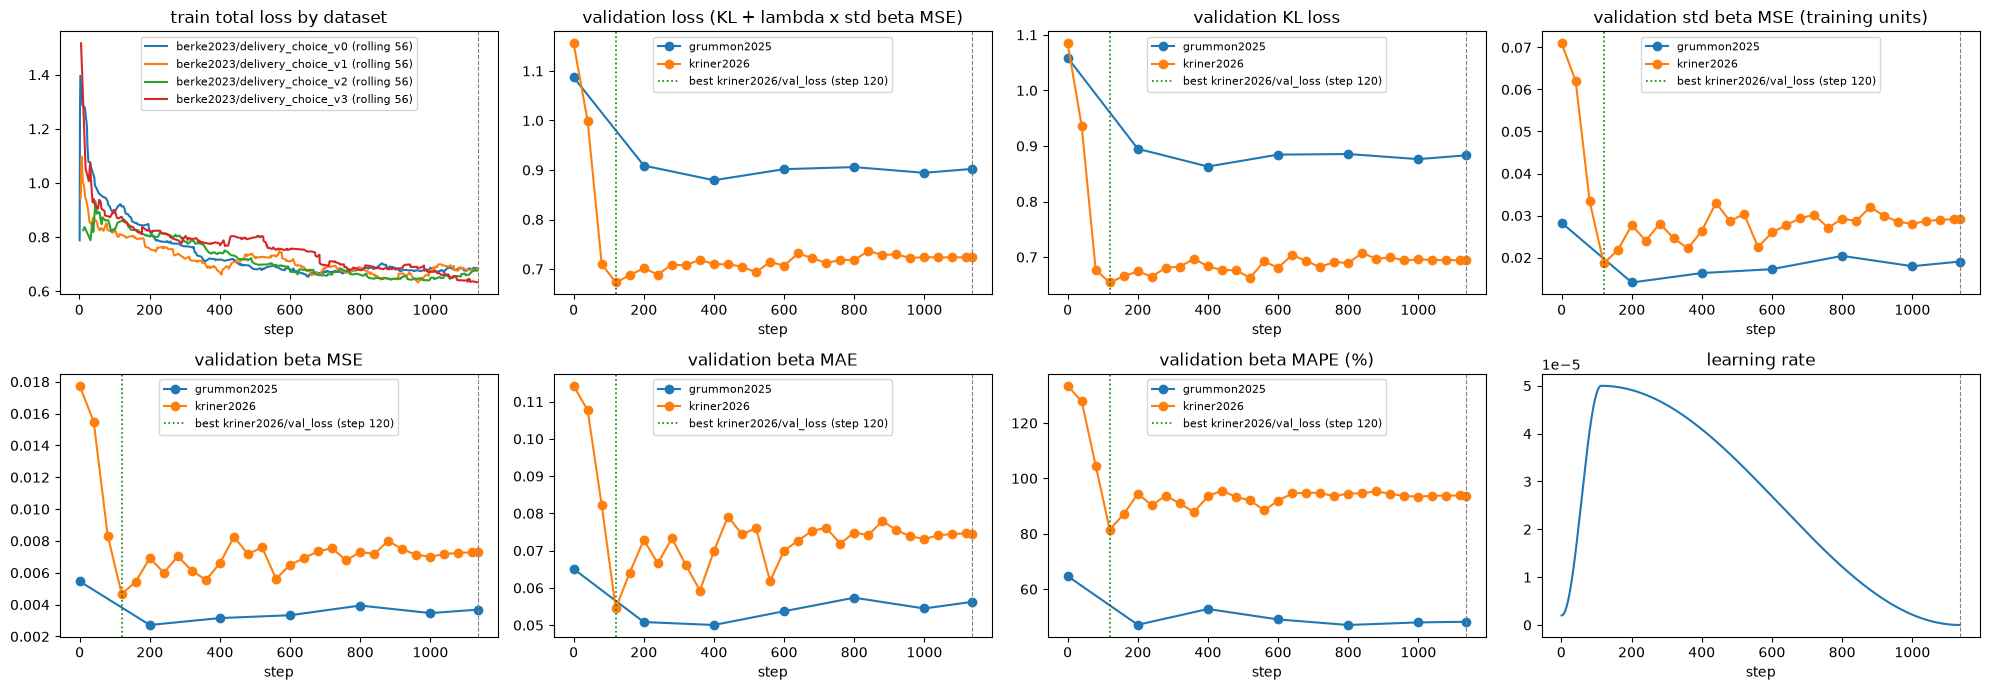

berke2023/delivery_choice_v0+berke2023/delivery_choice_v1+berke2023/delivery_choice_v2+berke2023/delivery_choi…

pass 1 (forward):   0%|          | 0/4 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/4 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/4 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/4 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/4 [00:00<?, ?it/s]

... (1,164 outputs left out)

Evaluating grummon2025_validation (shared-state):   0%|          | 0/35 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating grummon2025_validation (shared-state):   0%|          | 0/35 [00:00<?, ?batch/s]

best.pt (step 120) validated at the end on: grummon2025


In [13]:
# Sample size 32
sample_size = 32
run_config = sample_size_config(sample_size)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

,epoch,rows_seen,train_loss,grummon2025/val_loss,grummon2025/std_beta_mse,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,kriner2026/val_loss,kriner2026/std_beta_mse,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,lr,grummon2025/eval_wall_sec,kriner2026/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,1.08718,0.02828,1.05890,0.00546,0.06510,64.72026,0.50000,1.15581,0.07099,1.08483,0.01775,0.11425,133.43868,-0.26573,NaN,66.59824,9.43978,0.00000
20,1,1280,0.92987,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.07348,0.06284,1.01064,0.01571,0.10915,131.68470,-0.18182,0.00001,NaN,11.44961,35.55525
40,1,2560,0.66741,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.77164,0.03238,0.73926,0.00809,0.08099,101.88880,0.21678,0.00004,NaN,11.43806,71.21794
60,1,3813,0.71007,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.70756,0.03355,0.67401,0.00839,0.08098,97.88870,0.35664,0.00005,NaN,11.42548,106.34308
80,1,5093,0.64495,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.69150,0.02608,0.66542,0.00652,0.07177,92.56388,0.53147,0.00005,NaN,11.39334,141.89825
100,1,6373,0.66110,0.90635,0.01400,0.89236,0.00270,0.04619,36.73399,0.50000,0.68480,0.02337,0.66143,0.00584,0.06763,89.31570,0.53846,0.00005,64.27730,11.56256,177.61545
120,1,7653,0.63942,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.69326,0.02391,0.66935,0.00598,0.06817,88.59227,0.52448,0.00005,NaN,11.96589,213.48790
140,1,8933,0.59060,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.70317,0.02297,0.68020,0.00574,0.06639,87.59881,0.53147,0.00005,NaN,11.82579,249.24079
160,1,10168,0.61963,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.72049,0.02097,0.69953,0.00524,0.05831,86.15918,0.41958,0.00005,NaN,11.93100,283.67712


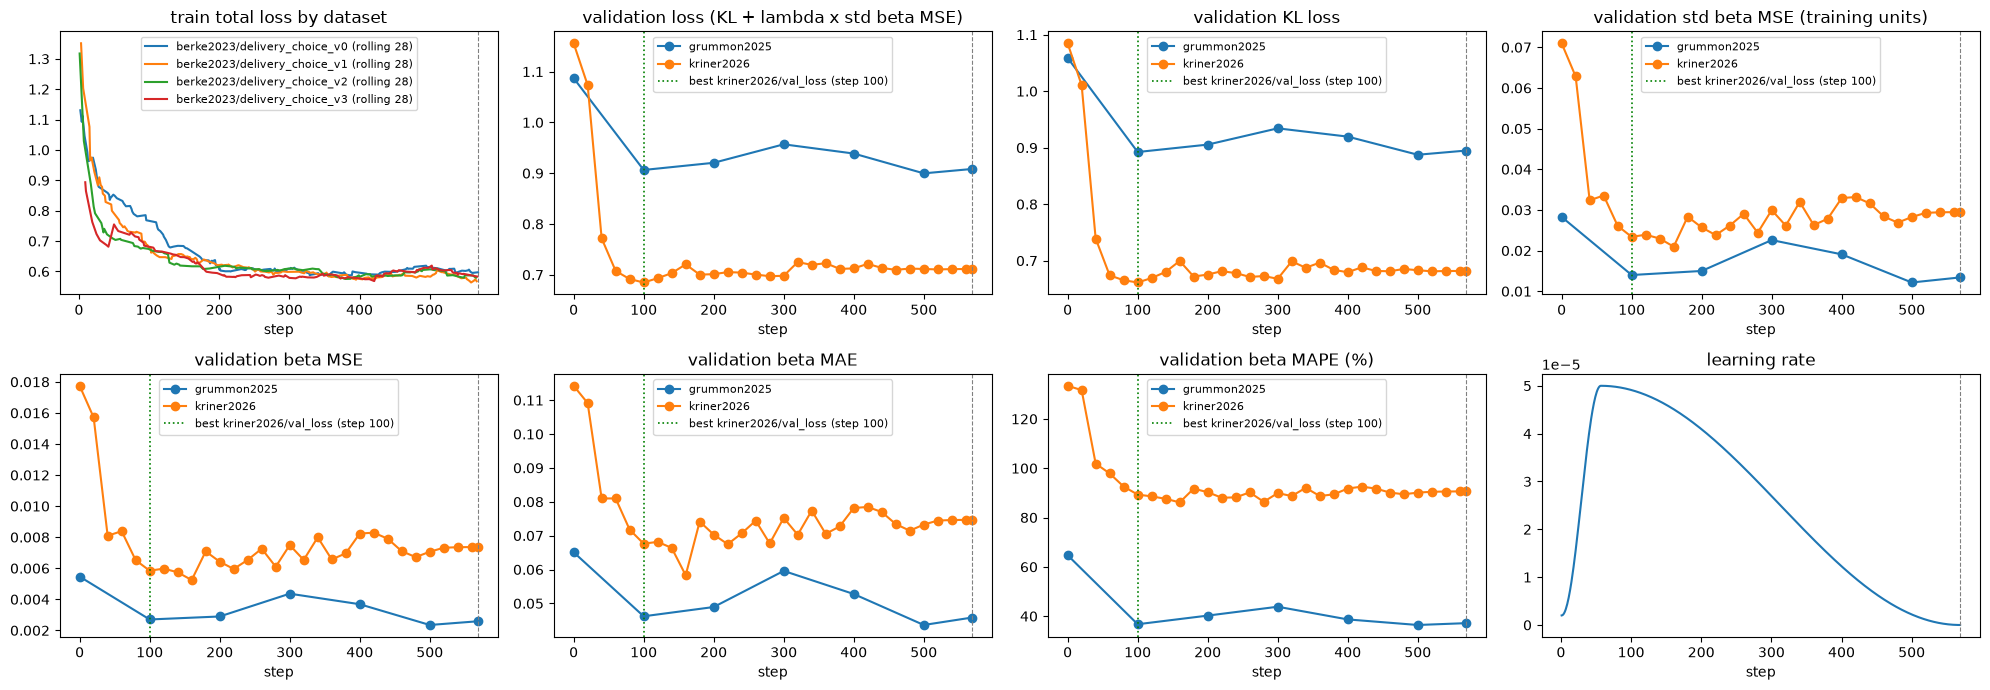

berke2023/delivery_choice_v0+berke2023/delivery_choice_v1+berke2023/delivery_choice_v2+berke2023/delivery_choi…

pass 1 (forward): 0it [00:00, ?it/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating grummon2025_validation (shared-state):   0%|          | 0/35 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

... (12 outputs left out)

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating grummon2025_validation (shared-state):   0%|          | 0/35 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

In [10]:
# Sample size 64
sample_size = 64
run_config = sample_size_config(sample_size)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

In [ ]:
# Sample size 256
sample_size = 256
run_config = sample_size_config(sample_size)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

In [ ]:
# Compare finished runs: final validation metrics, per-dataset train losses, and each validator's betas
display(comparison_table(runs, step0_validation).round(5))
display(per_dataset_table(runs).round(5))
for dataset_name in validators:
    display(eval_beta_table(runs, step0_validation, dataset_name).round(4))

# The same runs at their best validation (by each run's best metric)
display(best_table(runs).round(5))
for dataset_name in validators:
    display(best_beta_table(runs, step0_validation, dataset_name).round(4))

In [ ]:
# Load every saved run of this notebook from disk (no training; works in a fresh kernel after the setup cells)
runs = {}
for saved_run_dir in sorted(RUNS_DIR.iterdir()):
    runs[saved_run_dir.name] = load_run(saved_run_dir)
display(pd.DataFrame([run.summary for run in runs.values()]).set_index("label"))

In [ ]:
# Put one run's best checkpoint into kev_model (e.g. to evaluate it further)
BEST_RUN_DIR = RUNS_DIR / run_name(sample_size_config(64))
best_checkpoint = load_best(BEST_RUN_DIR)
reset_trainable(kev_model, best_checkpoint["trainable"])
display(pd.Series(best_checkpoint["best"], name=BEST_RUN_DIR.name).to_frame())

In [ ]:
# Decompose each validator's beta MSE into per-beta squared errors across runs
for dataset_name in validators:
    display(mse_decomposition(runs, step0_validation, dataset_name).round(5))

# Cross-dataset beta scale and sample-size target noise

In [ ]:
# Compare raw vs sigma_y-standardized human beta mean-square across the loaded datasets
scale_rows = []
for dataset_name, tidy in human_ols_by_dataset.items():
    choice_df = choice_dfs[dataset_name]
    option_counts = sorted({len(one_hot) for one_hot in choice_df["one_hot"]})
    sigma_by_model = tidy.groupby("model", sort=False)["sigma_y"].first()
    scale_rows.append(
        {
            "dataset": dataset_name,
            "respondents": choice_df["CASEID"].nunique(),
            "tasks": len(choice_df),
            "options_per_task": ", ".join(str(n) for n in option_counts),
            "regressions": len(sigma_by_model),
            "num_betas": len(tidy),
            "sigma_y": ", ".join(f"{sigma:.4g}" for sigma in sigma_by_model),
            "raw_signal_beta_ms": float((tidy["human_beta"] ** 2).mean()),
            "std_signal_beta_ms": float((tidy["std_beta"] ** 2).mean()),
        }
    )
display(pd.DataFrame(scale_rows).set_index("dataset").round(5))

# Rank deficiency

In [ ]:
# Target noise of sample betas vs row sample size (Monte Carlo over data rows = training items), per regression
for SNR_DATASET in TRAIN_DATASETS:  
    SNR_SAMPLE_SIZES = [16, 32, 64, 128, 256]
    SNR_DRAWS = 4000

    beta_noise_df = beta_core.beta_noise_by_sample_size(
        regression_rows_by_dataset[SNR_DATASET],
        regression_specs_by_dataset[SNR_DATASET],
        SNR_SAMPLE_SIZES,
        SNR_DRAWS,
        seed=42,
    )
    display(beta_noise_df.set_index(["model", "sample_size"]).round(4))

# Test micro-batching

In [ ]:
# Two-pass micro-chunked gradient (training) vs one backward through the whole sample
CHECK_DATASET = "grummon2023"   # any key of `unified_items`
CHECK_SAMPLE_SIZE = 15          # one graph of this many items (rows) must fit in VRAM (method A)
CHECK_MICRO_CHUNK = 3           # items (data rows) per chunk
CHECK_BETA_LAMBDA = 5.0         # > 0 so both KL and beta gradients are tested

gradient_check_result = gradient_check(
    kev_model,
    unified_items[CHECK_DATASET],
    regression_specs_by_dataset[CHECK_DATASET],
    INIT_TRAINABLE_STATE,
    sample_size=CHECK_SAMPLE_SIZE,
    micro_chunk=CHECK_MICRO_CHUNK,
    beta_lambda=CHECK_BETA_LAMBDA,
    seed=0,
    device=device,
)
display(pd.Series(gradient_check_result, name="gradient_check").to_frame())

# Overfit first

In [ ]:
# Overfit sanity check: many passes with pure KL/CE, constant LR, and zero weight decay
BASE_LR_SAMPLE_1 = 2e-5   # validated 1-respondent/step LR; scaled by sqrt(sample size)

OVERFIT_CONFIG = TrainConfig(
    train_datasets=("grummon2023",),
    sample_size_by_dataset={"grummon2023": 128},
    beta_lambda=0.0,
    lr=scale_lr_for_sample_size(BASE_LR_SAMPLE_1, 128),
    num_epochs=10,
    eval_every_by_validator={name: math.ceil(len(unified_items["grummon2023"]) / 128) for name in VALIDATION_DATASETS},   # one validation per epoch
    lr_schedule="constant",
    weight_decay=0.0,
    micro_chunk=MAX_FITTING_MICRO_CHUNK,
    gradient_checkpointing=SEARCH_GRADIENT_CHECKPOINTING,
    grad_clip=1.0,
    seed=42,
)
overfit_run = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=OVERFIT_CONFIG,
    device=device,
    run_dir=RUNS_DIR / f"overfit_{run_name(OVERFIT_CONFIG)}",
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)